### University of Virginia
### DS 5110: Big Data Systems
### K-Means Cluster Analysis of Fidelity Fund Returns 
### Last updated: March 11, 2023

## Instructions

In this assignment, you will conduct a k-means cluster analysis on a set of Fidelity mutual funds.  
This helps to group similar funds based on their performance (as opposed to their description, which is typical).  
The outline below will walk you through the required steps.  

This assignment is worth a total of **10 POINTS.**

## Data Details 

The file *fido_returns_funds_on_rows.csv* is the processed data for k-means. Additional details about this file: 
- Each row represents a mutual fund  
- Each column represents a trading day (these are used as features)  
- Each value represents the daily percentage change in price between the current trading day and previous trading day

### Load Modules and Read Data into Spark DataFrame

In [1]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
import pandas as pd

In [2]:
DATA_FILENAME = "fido_returns_funds_on_rows.csv"

spark = SparkSession \
    .builder \
    .appName("fido_kmeans") \
    .getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/16 15:50:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
fido_df = spark.read.csv(DATA_FILENAME, inferSchema=True, header=True)

**(VALUE: 2 POINTS) Assemble the Features into a column. 
Show the first five rows of data ONLY for the features column.
(this should make things easier to read)**

In [4]:
feats = inputCols=fido_df.columns
assembler = VectorAssembler(inputCols=feats, outputCol="features")
assembled_df = assembler.transform(fido_df)
assembled_df.select("features").show(5)

26/10/16 15:50:12 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 2:>                                                          (0 + 1) / 1]

+--------------------+
|            features|
+--------------------+
|[0.0,0.0,-0.01040...|
|[0.0,0.0,-0.01051...|
|[0.0,0.0,-0.01076...|
|[0.0,8.26105E-4,-...|
|[0.0,8.2815740000...|
+--------------------+
only showing top 5 rows


**(VALUE: 1 POINT) Set up the k-means model and train the model**  
Use parameters: 
- 3 clusters
- maximum of 10 iterations 
- seed=314

In [5]:
kmeans = KMeans(k=3, maxIter=10, seed=314)
model = kmeans.fit(assembled_df)

26/10/16 15:50:20 WARN DAGScheduler: Broadcasting large task binary with size 1006.3 KiB
                                                                                

**(VALUE: 2 POINTS) Compute and Print the Silhouette Score**  

In [6]:
predictions = model.transform(assembled_df)
predictions.select("prediction").show(5)

+----------+
|prediction|
+----------+
|         0|
|         0|
|         0|
|         2|
|         2|
+----------+
only showing top 5 rows


In [7]:
evaluator = ClusteringEvaluator()

silhouette = evaluator.evaluate(predictions)
print("Silhouette with squared euclidean distance = " + str(silhouette))

print("Cluster Centers: ")
centers = model.clusterCenters()
print(centers)

Silhouette with squared euclidean distance = 0.4229091846122795
Cluster Centers: 
[array([ 0.        ,  0.00048524, -0.00300457, ...,  0.00115682,
       -0.00934959,  0.00567394], shape=(1731,)), array([ 0.        ,  0.00039189, -0.00063383, ...,  0.00123677,
       -0.00342282, -0.00089758], shape=(1731,)), array([ 0.        , -0.00124346, -0.00686847, ...,  0.00213042,
       -0.01411085,  0.0100746 ], shape=(1731,))]


**(VALUE: 2 POINTS) Define a function `kmeans_range()` that does the following:**
- takes an integer representing the lower bound for k
- takes an integer representing the upper bound for k
- take a Spark DataFrame containing training data
- fit K-means with k ranging from lower bound to upper bound, inclusive  
- the other parameters should be the same as earlier 
- for each k, compute the silhouette score
- return a pandas dataframe with columns containing k, silhouette score (each row holds the score for given k)

In [8]:
def kmeans_range(lower, upper, train_df):
    evaluator = ClusteringEvaluator()
    sil_scores = []
    
    for k in range(lower, upper+1):
        kmeans = KMeans(k=k, maxIter=10, seed=314)
        model = kmeans.fit(train_df)

        predictions = model.transform(train_df)

        sil_scores.append(evaluator.evaluate(predictions))

    data = {'k': range(lower, upper+1),
            'silhouette': sil_scores}
    scores_df = pd.DataFrame(data)
    return scores_df

**(VALUE: 1 POINT) Call `kmeans_range` to compute K-means with clusters ranging from 2 to 10 inclusive, printing the resulting dataframe.**

In [9]:
lower = 2
upper = 10

scores_df = kmeans_range(lower, upper, assembled_df)

26/10/16 15:50:29 WARN DAGScheduler: Broadcasting large task binary with size 1006.3 KiB
26/10/16 15:50:34 WARN DAGScheduler: Broadcasting large task binary with size 1019.8 KiB
26/10/16 15:50:38 WARN DAGScheduler: Broadcasting large task binary with size 1033.4 KiB
26/10/16 15:50:42 WARN DAGScheduler: Broadcasting large task binary with size 1046.9 KiB
26/10/16 15:50:46 WARN DAGScheduler: Broadcasting large task binary with size 1060.5 KiB
26/10/16 15:50:50 WARN DAGScheduler: Broadcasting large task binary with size 1074.0 KiB
26/10/16 15:50:54 WARN DAGScheduler: Broadcasting large task binary with size 1087.5 KiB
26/10/16 15:50:58 WARN DAGScheduler: Broadcasting large task binary with size 1101.1 KiB


In [10]:
scores_df

,k,silhouette
0,2,0.602396
1,3,0.422909
2,4,0.448951
3,5,0.459352
4,6,0.468879
5,7,0.459371
6,8,0.477168
7,9,0.431599
8,10,0.438814


**(VALUE: 1 POINT) Produce a plot with cluster numbers k on the x-axis, sihouette scores on the y-axis**

<Axes: title={'center': 'Silhouette Score by k'}, xlabel='Number of clusters (k)', ylabel='Silhouette score'>

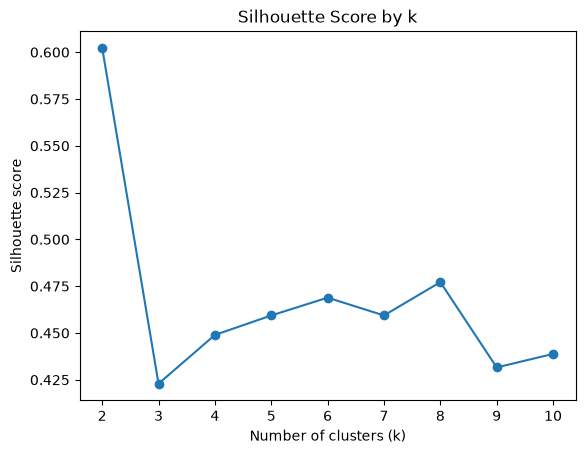

In [11]:
scores_df.plot(x = 'k', y = 'silhouette',
               marker = "o",
               title = "Silhouette Score by k",
               xlabel = "Number of clusters (k)",
               ylabel = "Silhouette score",
               legend = False)

**(VALUE: 1 POINT) Based on how the silhouette score is calculated, what is its time complexity? (e.g., O(log n))**  
You can find the definition of the silhouette score in the lecture notes, for example. 

The time complexity for calculating silhouette score is $O(n^2)$ because while the A and B values only require the intra-cluster distances and nearest-cluster distances, the nearest cluster is determined by measuring distance from one point to all other points, and must be done for every point.